In [1]:
%load_ext autoreload
%autoreload 2  
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent)) 
from sst2 import *

train, validation, test = load_sst2()
tokenizer = get_tokenizer(train)
cv_sets = get_cv_splits(train)

In [2]:
import json
from pathlib import Path

import torch
from part1.experiment import cross_validation_experiment

dropout_results = {}

for dropout in [0.1, 0.3, 0.5]:
    accuracies = []

    for fold, split in cv_sets[0].items():
        torch.manual_seed(fold)  # same starting weights for every dropout rate
        fold_result = cross_validation_experiment(
            data_splits={fold: split},
            outcome_space=CLASSES,
            encoder=BagOfWords(tokenizer),
            model_option="mlp",
            save_to=f"result2/bow-dropout-{dropout}/seed-0",
            smlp_args={"dropout": dropout},
        )
        accuracies.append(float(fold_result["accuracies"][fold]))

    dropout_results[str(dropout)] = accuracies

Path("result2").mkdir(exist_ok=True)
with open("result2/dropout_results.json", "w") as f:
    json.dump(dropout_results, f, indent=2)


  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 19.676 seconds
Dataloader done! Time taken: 2.194 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

/Users/stone/Desktop/nlp1-group15/part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:256.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)


Epoch 01 | train loss: 0.3784 | train acc: 0.8301 | val loss: 0.2703 | val acc: 0.8867
Epoch 02 | train loss: 0.2216 | train acc: 0.9123 | val loss: 0.2303 | val acc: 0.9116
Epoch 03 | train loss: 0.1589 | train acc: 0.9397 | val loss: 0.2181 | val acc: 0.9193
Epoch 04 | train loss: 0.1187 | train acc: 0.9565 | val loss: 0.2207 | val acc: 0.9216
Epoch 05 | train loss: 0.0919 | train acc: 0.9664 | val loss: 0.2274 | val acc: 0.9246
Epoch 06 | train loss: 0.0744 | train acc: 0.9746 | val loss: 0.2347 | val acc: 0.9274
Epoch 07 | train loss: 0.0595 | train acc: 0.9796 | val loss: 0.2534 | val acc: 0.9261
Epoch 08 | train loss: 0.0514 | train acc: 0.9828 | val loss: 0.2642 | val acc: 0.9258
Epoch 09 | train loss: 0.0445 | train acc: 0.9856 | val loss: 0.2748 | val acc: 0.9274
Epoch 10 | train loss: 0.0403 | train acc: 0.9873 | val loss: 0.2832 | val acc: 0.9280
Epoch 11 | train loss: 0.0357 | train acc: 0.9892 | val loss: 0.2883 | val acc: 0.9272
Epoch 12 | train loss: 0.0326 | train acc: 

  0%|          | 0/1 [00:00<?, ?it/s]

... (51 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 18.927 seconds
Dataloader done! Time taken: 2.041 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4037 | train acc: 0.8135 | val loss: 0.2878 | val acc: 0.8799
Epoch 02 | train loss: 0.2475 | train acc: 0.9020 | val loss: 0.2471 | val acc: 0.9030
Epoch 03 | train loss: 0.1952 | train acc: 0.9246 | val loss: 0.2368 | val acc: 0.9102
Epoch 04 | train loss: 0.1611 | train acc: 0.9401 | val loss: 0.2307 | val acc: 0.9182
Epoch 05 | train loss: 0.1358 | train acc: 0.9502 | val loss: 0.2305 | val acc: 0.9225
Epoch 06 | train loss: 0.1162 | train acc: 0.9587 | val loss: 0.2375 | val acc: 0.9213
Epoch 07 | train loss: 0.1032 | train acc: 0.9632 | val loss: 0.2424 | val acc: 0.9230
Epoch 08 | train loss: 0.0935 | train acc: 0.9677 | val loss: 0.2498 | val acc: 0.9230
Epoch 09 | train loss: 0.0826 | train acc: 0.9709 | val loss: 0.2570 | val acc: 0.9260
Epoch 10 | train loss: 0.0732 | train acc: 0.9753 | val loss: 0.2656 | val acc: 0.9252
Epoch 11 | train loss: 0.0675 | train acc: 0.9772 | val loss: 0.2777 | val acc: 0.9265
Epoch 12 | train loss: 0.0621 | train acc: 

dropout=0.1: mean=0.9141 std=0.0027
dropout=0.3: mean=0.9180 std=0.0028
dropout=0.5: mean=0.9197 std=0.0030
A=0.1 B=0.3: P(A wins)=0.0080 P(Tie)=0.6754 P(B wins)=0.3166 Effect Size=1.75


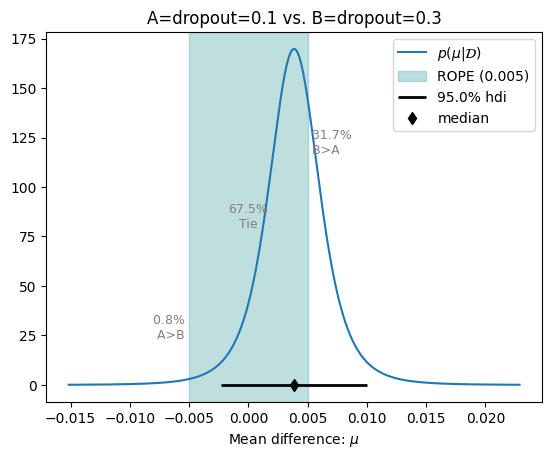

A=0.1 B=0.5: P(A wins)=0.0046 P(Tie)=0.4041 P(B wins)=0.5913 Effect Size=2.47


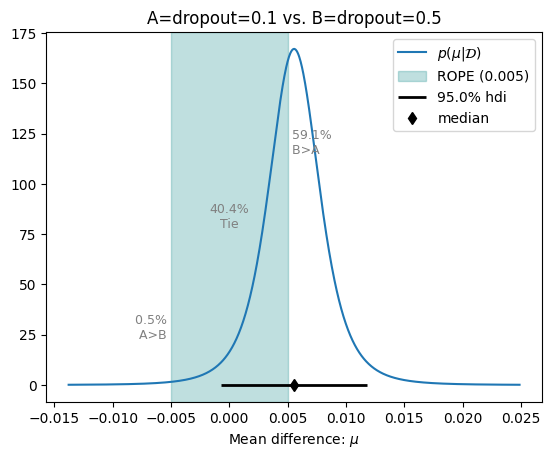

A=0.3 B=0.5: P(A wins)=0.0000 P(Tie)=0.9993 P(B wins)=0.0007 Effect Size=4.04


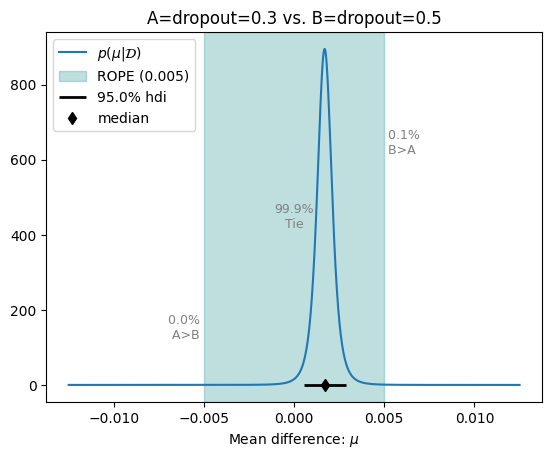

In [3]:
import json
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from part1.analysis import BenavoliCorrelatedT

rope = 0.005

with open("result2/dropout_results.json") as f:
    dropout_results = json.load(f)

for name, scores in dropout_results.items():
    print(f"dropout={name}: mean={np.mean(scores):.4f} std={np.std(scores):.4f}")

for name_a, name_b in combinations(dropout_results, 2):
    posterior = BenavoliCorrelatedT(
        dropout_results[name_a],
        dropout_results[name_b],
        runs=1,
        names=[f"dropout={name_a}", f"dropout={name_b}"],
    )
    p_a, p_tie, p_b = posterior.probs(rope)
    print(f"A={name_a} B={name_b}: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")

    fig, ax = posterior.plot(rope)
    fig.savefig(f"result2/compare_{name_a}_vs_{name_b}.png", dpi=150, bbox_inches="tight")
    plt.show()
